# Foundations of Generative AI — Assignment 2
## Autoregressive Science-Fiction Text Generation with RNN, BiRNN, LSTM and GRU

**Environment:** Google Colab (Runtime → Change runtime type → GPU is optional)  
**Dataset:** The War of the Worlds by H. G. Wells  
**Task:** Train four recurrent neural models to predict the next word, compare quantitative metrics, and study temperature-based generation.

> Run cells from top to bottom. The notebook downloads the dataset, trains the models, writes result files, and creates plots. Report only the metrics produced by your actual run.


## 1. Setup and reproducibility
This notebook uses TensorFlow/Keras. It caps the corpus and vocabulary to keep the experiment manageable on a free notebook runtime. All four models use the same train/validation split and broadly comparable settings.

In [1]:
import os, re, time, random, json, math, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

OUTPUT_DIR = Path("/content/results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download and inspect the dataset
The dataset is the public-domain novel *The War of the Worlds* by H. G. Wells, obtained from Project Gutenberg. We use it as a word-level next-token prediction dataset.

In [2]:
DATA_URL = "https://www.gutenberg.org/cache/epub/36/pg36.txt"
DATA_PATH = "/content/war_of_the_worlds.txt"

urllib.request.urlretrieve(DATA_URL, DATA_PATH)
raw_text = Path(DATA_PATH).read_text(encoding="utf-8")

# Remove Project Gutenberg's license header/footer when present.
start_marker = "*** START OF THE PROJECT GUTENBERG EBOOK"
end_marker = "*** END OF THE PROJECT GUTENBERG EBOOK"
if start_marker in raw_text:
    raw_text = raw_text.split(start_marker, 1)[1]
    raw_text = raw_text.split("\n", 1)[1] if "\n" in raw_text else raw_text
if end_marker in raw_text:
    raw_text = raw_text.split(end_marker, 1)[0]

print("Dataset: The War of the Worlds by H. G. Wells")
print("Characters:", len(raw_text))
print("Preview:\n", raw_text[:700])


Dataset: The War of the Worlds by H. G. Wells
Characters: 337429
Preview:
 
/


The War of the Worlds

by H. G. Wells




   ‘But who shall dwell in these worlds if they be inhabited?
    . . . Are we or they Lords of the World? . . . And
    how are all things made for man?’
                    KEPLER (quoted in _The Anatomy of Melancholy_)




Contents


 BOOK ONE.—THE COMING OF THE MARTIANS

 I. THE EVE OF THE WAR.
 II. THE FALLING STAR.
 III. ON HORSELL COMMON.
 IV. THE CYLINDER OPENS.
 V. THE HEAT-RAY.
 VI. THE HEAT-RAY IN THE CHOBHAM ROAD.
 VII. HOW I REACHED HOME.
 VIII. FRIDAY NIGHT.
 IX. THE FIGHTING BEGINS.
 X. IN THE STORM.
 XI. AT THE WINDOW.
 XII. WHAT I SAW OF THE DESTRUCTION OF WEYBRIDGE AND SHEPPERTON.
 XIII. HOW I FELL IN WITH THE CURATE.
 XIV. IN 


## 3. Preprocess text and construct next-word sequences
We normalize to lowercase, retain words and common punctuation, tokenize the corpus, and limit the vocabulary. Each input consists of the previous `SEQ_LEN` tokens and the target is the immediately following token. The split is chronological to reduce leakage from future text into training.

In [3]:
# Keep words and punctuation as separate tokens; normalize whitespace.
text = raw_text.lower()
text = re.sub(r"[^a-z0-9'!?.,;:\\-]+", " ", text)
text = re.sub(r"\s+", " ", text).strip()

MAX_WORDS = 8000
SEQ_LEN = 20
MAX_TOKENS = 120_000  # cap corpus size for a practical free-runtime experiment

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<unk>", filters="")
tokenizer.fit_on_texts([text])
all_ids = tokenizer.texts_to_sequences([text])[0][:MAX_TOKENS]

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)
# Keras reserves index 1 for OOV; only keep ids within the chosen vocabulary.
all_ids = [idx if idx < vocab_size else 1 for idx in all_ids]

# Use a stride of 3 to reduce highly overlapping examples and runtime.
stride = 3
starts = np.arange(0, len(all_ids) - SEQ_LEN, stride)
X = np.zeros((len(starts), SEQ_LEN), dtype=np.int32)
y = np.zeros((len(starts),), dtype=np.int32)
for i, start in enumerate(starts):
    X[i] = all_ids[start:start + SEQ_LEN]
    y[i] = all_ids[start + SEQ_LEN]

split_at = int(0.90 * len(X))
X_train, y_train = X[:split_at], y[:split_at]
X_val, y_val = X[split_at:], y[split_at:]

print(f"Vocabulary size: {vocab_size}")
print(f"Tokens used: {len(all_ids):,}")
print(f"Examples: {len(X):,} | train: {len(X_train):,} | validation: {len(X_val):,}")
print("Example input:", tokenizer.sequences_to_texts([X_train[0]])[0])
print("Target word:", tokenizer.index_word.get(int(y_train[0]), "<unk>"))

Vocabulary size: 8000
Tokens used: 60,762
Examples: 20,248 | train: 18,223 | validation: 2,025
Example input: the war of the worlds by h. g. wells but who shall dwell in these worlds if they be inhabited?
Target word: .


## 4. Build the four comparable models
Each model receives a sequence of 20 word IDs, embeds them, processes the sequence with its recurrent layer, and predicts a probability distribution over the next word. The Bidirectional RNN reads both directions **within the supplied seed/history window**; it does not receive future target tokens.

In [4]:
EMBED_DIM = 96
RNN_UNITS = 128
BATCH_SIZE = 128
EPOCHS = 5

def build_model(model_type):
    inputs = layers.Input(shape=(SEQ_LEN,), dtype="int32")
    x = layers.Embedding(vocab_size, EMBED_DIM, mask_zero=False)(inputs)

    if model_type == "Simple RNN":
        x = layers.SimpleRNN(RNN_UNITS)(x)
    elif model_type == "Bidirectional RNN":
        x = layers.Bidirectional(layers.SimpleRNN(RNN_UNITS))(x)
    elif model_type == "LSTM":
        x = layers.LSTM(RNN_UNITS)(x)
    elif model_type == "GRU":
        x = layers.GRU(RNN_UNITS)(x)
    else:
        raise ValueError("Unknown model type")

    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(vocab_size, activation="softmax")(x)
    model = models.Model(inputs, outputs, name=model_type.lower().replace(" ", "_"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["sparse_categorical_accuracy"]
    )
    return model

model_types = ["Simple RNN", "Bidirectional RNN", "LSTM", "GRU"]


## 5. Train and evaluate all models
We record training time, best validation loss, validation next-word accuracy, and perplexity (`exp(validation loss)`). Perplexity is a standard language-model metric; lower values are better. Training time depends on the runtime hardware and should be reported from your run.

In [13]:
histories = {}
trained_models = {}
rows = []

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(
    min(len(X_train), 20000), seed=SEED, reshuffle_each_iteration=True
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

for model_type in model_types:
    print("\\n" + "=" * 70)
    print("Training:", model_type)
    model = build_model(model_type)
    start_time = time.time()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1,
        callbacks=[tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True
        )]
    )
    elapsed = time.time() - start_time
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    perplexity = float(np.exp(min(val_loss, 20)))  # guard against overflow
    histories[model_type] = history.history
    trained_models[model_type] = model
    rows.append({
        "Model": model_type,
        "Training time (seconds)": round(elapsed, 2),
        "Best validation loss": round(float(min(history.history["val_loss"])), 4),
        "Validation loss": round(float(val_loss), 4),
        "Validation next-word accuracy": round(float(val_acc), 4),
        "Perplexity": round(perplexity, 3),
        "Epochs completed": len(history.history["loss"])
    })

results = pd.DataFrame(rows).sort_values("Validation loss").reset_index(drop=True)
display(results)
results.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
print("Saved:", OUTPUT_DIR / "model_comparison.csv")


\n======================================================================
Training: Simple RNN
Epoch 1/5
143/143 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 7.1425 - sparse_categorical_accuracy: 0.0690 - val_loss: 6.2932 - val_sparse_categorical_accuracy: 0.0864
Epoch 2/5
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.7545 - sparse_categorical_accuracy: 0.0748 - val_loss: 6.2707 - val_sparse_categorical_accuracy: 0.0864
Epoch 3/5
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.4085 - sparse_categorical_accuracy: 0.0860 - val_loss: 6.2542 - val_sparse_categorical_accuracy: 0.1205
Epoch 4/5
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.2168 - sparse_categorical_accuracy: 0.0969 - val_loss: 6.2199 - val_sparse_categorical_accuracy: 0.1378
Epoch 5/5
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.0110 - sparse_categorical_accuracy: 0.1052 - val_loss: 6.2649 - val_sparse_categorical_accuracy: 0.1259
\n======================================================================
Trainin

,Model,Training time (seconds),Best validation loss,Validation loss,Validation next-word accuracy,Perplexity,Epochs completed
0,GRU,7.29,6.1385,6.1385,0.1353,463.337,5
1,Bidirectional RNN,12.16,6.1445,6.1445,0.1467,466.144,5
2,LSTM,7.13,6.2157,6.2157,0.0864,500.543,4
3,Simple RNN,9.27,6.2199,6.2199,0.1378,502.665,5


Saved: /content/results/model_comparison.csv


## 6. Plot training curves and compare models
Use these plots and the results table in the report. Do not assume a particular architecture wins before looking at your measured results.

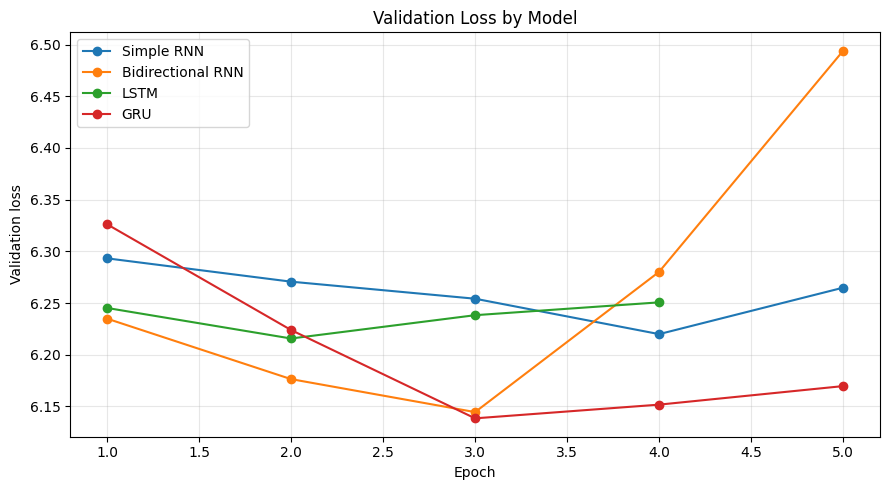

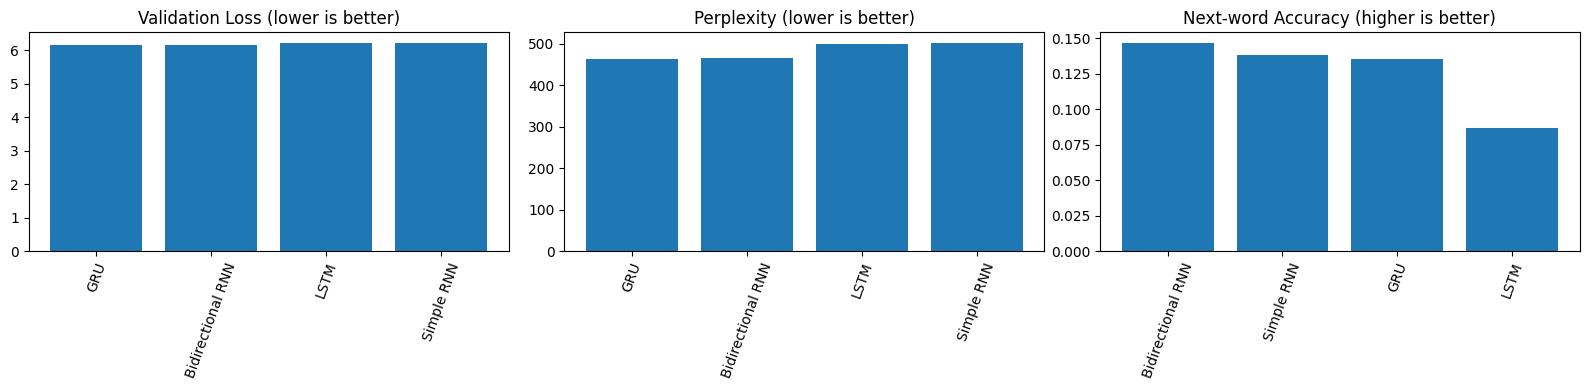

In [15]:
# Validation-loss curves
plt.figure(figsize=(9, 5))
for name, history in histories.items():
    plt.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Validation Loss by Model")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "validation_loss_curves.png", dpi=160)
plt.show()

# Compare core metrics
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric, title in zip(
    axes,
    ["Validation loss", "Perplexity", "Validation next-word accuracy"],
    ["Validation Loss (lower is better)", "Perplexity (lower is better)", "Next-word Accuracy (higher is better)"]
):
    plot_df = results.sort_values(metric, ascending=("Accuracy" not in title))
    ax.bar(plot_df["Model"], plot_df[metric])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=70)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_metric_comparison.png", dpi=160)
plt.show()


## 7. Generate text with temperature sampling
Temperature rescales the model's predicted logits before sampling: lower temperatures generally make outputs more predictable, while higher temperatures usually increase variety and may also increase incoherence. We use the same seed and the same temperatures for all models.

In [16]:
# Optimized text generation for all four models

SEED_TEXTS = [
    "the strange machine",
    "the earth was",
    "the red planet"
]

TEMPERATURES = [0.5, 1.0, 1.5]
GEN_WORDS = 25

index_word = tokenizer.index_word

def sample_from_probs(probs, temperature=1.0):
    probs = np.asarray(probs, dtype=np.float64)
    probs = np.log(np.maximum(probs, 1e-9)) / temperature
    probs -= np.max(probs)
    probs = np.exp(probs)
    probs /= probs.sum()

    return int(np.random.choice(len(probs), p=probs))


def generate_text(model, seed_text, temperature=1.0, num_words=25):
    seed_tokens = tokenizer.texts_to_sequences(
        [seed_text.lower()]
    )[0]

    seed_tokens = [
        idx if idx < vocab_size else 1
        for idx in seed_tokens
    ]

    if not seed_tokens:
        seed_tokens = [1]

    generated = list(seed_tokens)

    for _ in range(num_words):
        context = generated[-SEQ_LEN:]
        context = [1] * max(0, SEQ_LEN - len(context)) + context

        # Faster than model.predict() for a single sequence
        probs = model(
            tf.constant([context], dtype=tf.int32),
            training=False
        ).numpy()[0]

        next_id = sample_from_probs(probs, temperature)

        if next_id == 0:
            next_id = 1

        generated.append(next_id)

    return " ".join(
        index_word.get(idx, "<unk>")
        for idx in generated
    )


samples = []

total = (
    len(trained_models)
    * len(SEED_TEXTS)
    * len(TEMPERATURES)
)

completed = 0

for model_type, model in trained_models.items():
    for seed_text in SEED_TEXTS:
        for temperature in TEMPERATURES:

            generated = generate_text(
                model,
                seed_text,
                temperature,
                GEN_WORDS
            )

            samples.append({
                "Model": model_type,
                "Seed": seed_text,
                "Temperature": temperature,
                "Generated text": generated
            })

            completed += 1
            print(f"Progress: {completed}/{total}")

samples_df = pd.DataFrame(samples)

samples_df.to_csv(
    OUTPUT_DIR / "generated_samples.csv",
    index=False
)

with open(
    OUTPUT_DIR / "generated_samples.txt",
    "w",
    encoding="utf-8"
) as f:
    for row in samples:
        f.write(
            f"MODEL: {row['Model']} | "
            f"SEED: {row['Seed']} | "
            f"TEMPERATURE: {row['Temperature']}\n"
        )
        f.write(row["Generated text"] + "\n\n")
        f.write("-" * 80 + "\n\n")

display(samples_df.head(12))

print(f"Generated {len(samples_df)} text samples.")
print("Results saved successfully.")

Progress: 1/36
Progress: 2/36
Progress: 3/36
Progress: 4/36
Progress: 5/36
Progress: 6/36
Progress: 7/36
Progress: 8/36
Progress: 9/36
Progress: 10/36
Progress: 11/36
Progress: 12/36
Progress: 13/36
Progress: 14/36
Progress: 15/36
Progress: 16/36
Progress: 17/36
Progress: 18/36
Progress: 19/36
Progress: 20/36
Progress: 21/36
Progress: 22/36
Progress: 23/36
Progress: 24/36
Progress: 25/36
Progress: 26/36
Progress: 27/36
Progress: 28/36
Progress: 29/36
Progress: 30/36
Progress: 31/36
Progress: 32/36
Progress: 33/36
Progress: 34/36
Progress: 35/36
Progress: 36/36


,Model,Seed,Temperature,Generated text
0,Simple RNN,the strange machine,0.5,the strange machine we <unk> the too had the <...
1,Simple RNN,the strange machine,1.0,the strange machine the curate to are amid a t...
2,Simple RNN,the strange machine,1.5,the strange machine narrowly up man hinder wit...
3,Simple RNN,the earth was,0.5,the earth was <unk> the been and the common. o...
4,Simple RNN,the earth was,1.0,the earth was opinion spared escape; like bird...
5,Simple RNN,the earth was,1.5,the earth was tin at ran of vague drinking wit...
6,Simple RNN,the red planet,0.5,the red planet the <unk> was the martians of t...
7,Simple RNN,the red planet,1.0,the red planet had it time the multitude monst...
8,Simple RNN,the red planet,1.5,"the red planet rapped <unk> since once, and pr..."
9,Bidirectional RNN,the strange machine,0.5,"the strange machine a feet, of the <unk> a <un..."


Generated 36 text samples.
Results saved successfully.


## 8. Inspect temperature effects
Compare samples generated from the same seed. Discuss:
- **Coherence:** Does the text read like a connected phrase or sentence?
- **Diversity:** Does the output use varied words and constructions?
- **Contextual consistency:** Does it stay related to the seed and maintain a plausible continuation?
- **Repetition:** Are words or phrases repeated excessively?

Temperature does not guarantee quality: describe what you observe in your actual generated samples.

In [17]:
# Show one seed across all models and temperatures for convenient manual analysis.
chosen_seed = SEED_TEXTS[0]
subset = samples_df[samples_df["Seed"] == chosen_seed]
for _, row in subset.iterrows():
    print(f"\\n{row['Model']} | temperature={row['Temperature']}")
    print(row["Generated text"])
    print("-" * 90)


\nSimple RNN | temperature=0.5
the strange machine we <unk> the too had the <unk> the <unk> of the <unk> of <unk> the martian than that the decided of of the stood of
------------------------------------------------------------------------------------------
\nSimple RNN | temperature=1.0
the strange machine the curate to are amid a then hilton, artillery-man. evening attitudes, me, noisily, the doing of the how or unseen already and silence. no martians.
------------------------------------------------------------------------------------------
\nSimple RNN | temperature=1.5
the strange machine narrowly up man hinder within handling-machine welcome grey, was its the broken. trees, in similarly glare an pair fellow no morning, twice cut population near
------------------------------------------------------------------------------------------
\nBidirectional RNN | temperature=0.5
the strange machine a feet, of the <unk> a <unk> and the <unk> i the road the <unk> of the other of the martia

## 9. Automatically create a results summary
This cell generates a preliminary, evidence-based summary using the measured metrics. Add your qualitative observations from the generated samples before submitting.

In [18]:
best_loss_row = results.loc[results["Validation loss"].idxmin()]
best_acc_row = results.loc[results["Validation next-word accuracy"].idxmax()]
fastest_row = results.loc[results["Training time (seconds)"].idxmin()]

summary = f"""# Experimental Results Summary

## Quantitative findings
- Lowest validation loss: **{best_loss_row['Model']}** ({best_loss_row['Validation loss']:.4f}).
- Lowest perplexity: **{results.loc[results['Perplexity'].idxmin(), 'Model']}** ({results['Perplexity'].min():.3f}).
- Highest validation next-word accuracy: **{best_acc_row['Model']}** ({best_acc_row['Validation next-word accuracy']:.4f}).
- Fastest training run: **{fastest_row['Model']}** ({fastest_row['Training time (seconds)']:.2f} seconds).

## Temperature analysis
The notebook generated continuations for temperatures 0.5, 1.0, and 1.5 using identical seed phrases for all four models. Review `generated_samples.csv` and add specific examples of how coherence, diversity, contextual consistency, and repetition changed with temperature.

## Conclusion
Choose the most effective model by considering validation loss/perplexity, prediction accuracy, training cost, and the quality of the generated samples together. Do not select a model using only one metric. Insert your qualitative observations here before submission.
"""

(OUTPUT_DIR / "results_summary.md").write_text(summary, encoding="utf-8")
print(summary)


# Experimental Results Summary

## Quantitative findings
- Lowest validation loss: **GRU** (6.1385).
- Lowest perplexity: **GRU** (463.337).
- Highest validation next-word accuracy: **Bidirectional RNN** (0.1467).
- Fastest training run: **LSTM** (7.13 seconds).

## Temperature analysis
The notebook generated continuations for temperatures 0.5, 1.0, and 1.5 using identical seed phrases for all four models. Review `generated_samples.csv` and add specific examples of how coherence, diversity, contextual consistency, and repetition changed with temperature.

## Conclusion
Choose the most effective model by considering validation loss/perplexity, prediction accuracy, training cost, and the quality of the generated samples together. Do not select a model using only one metric. Insert your qualitative observations here before submission.



## 10. Download results
The files are saved in `/content/results`. Run the next cell to download a ZIP archive to your computer, then upload the notebook and relevant results to your GitHub repository.

In [19]:
import shutil
zip_path = shutil.make_archive("/content/fgai_assignment2_results", "zip", OUTPUT_DIR)
print("Created:", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Not running in Google Colab. Find the ZIP at:", zip_path)


Created: /content/fgai_assignment2_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Dataset and references
- Dataset: The War of the Worlds by H. G. Wells.
- Source: https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
- Framework: TensorFlow/Keras.
- Core evaluation: sparse categorical cross-entropy, next-word accuracy, perplexity, training time, and qualitative sample inspection.

## Before submission
1. Run every cell successfully.
2. Check that the comparison table and plots were produced.
3. Inspect generated samples and write specific qualitative observations.
4. Add your actual results and conclusion to `README.md`.
5. Upload the notebook, results, and README to GitHub.
6. Create the required Word document with your name, registration number, assignment title, project title, dataset source, and repository link, then export it to PDF.
